In [4]:
import os
os.chdir('../data')

In [5]:
import pandas as pd
df = pd.read_csv(r'MERGED/swe_merged.csv')
print(df.head())

         date  swe_m_snodas  swe_m_snotel
0  2004-03-01         0.325       0.34036
1  2004-03-02         0.353       0.34544
2  2004-03-03         0.353       0.35306
3  2004-03-04         0.353       0.35306
4  2004-03-05         0.369       0.36322


In [6]:
# Peak SWE and DOY data/table
import pandas as pd

# Load merged data
merged_df = pd.read_csv(r'MERGED/swe_merged.csv', parse_dates=['date'])

# Extract year
merged_df['year'] = merged_df['date'].dt.year

# Find peak SWE per year for each product
peaks_snodas = merged_df.loc[merged_df.groupby('year')['swe_m_snodas'].idxmax()][['year', 'date', 'swe_m_snodas']].rename(columns={'date': 'peak_date_snodas', 'swe_m_snodas': 'peak_swe_snodas'})

peaks_snotel = merged_df.loc[merged_df.groupby('year')['swe_m_snotel'].idxmax()][['year', 'date', 'swe_m_snotel']].rename(columns={'date': 'peak_date_snotel', 'swe_m_snotel': 'peak_swe_snotel'})

# Combine into one dataframe
peaks_df = pd.merge(peaks_snodas, peaks_snotel, on='year').reset_index(drop=True)

print(peaks_df.to_string())

# Save
peaks_df.to_csv(r'MERGED/peaks_swe.csv', index=False)

    year peak_date_snodas  peak_swe_snodas peak_date_snotel  peak_swe_snotel
0   2004       2004-04-25            0.464       2004-04-23          0.44196
1   2005       2005-05-04            0.583       2005-05-13          0.58420
2   2006       2006-04-19            0.633       2006-04-19          0.64770
3   2007       2007-05-02            0.840       2007-04-27          0.60960
4   2008       2008-06-14            1.135       2008-05-25          0.92964
5   2009       2009-05-16            0.842       2009-05-15          0.90678
6   2010       2010-05-14            0.562       2010-05-13          0.68580
7   2011       2011-06-01            0.737       2011-05-31          0.94234
8   2012       2012-05-08            0.523       2012-05-06          0.65532
9   2013       2013-05-21            0.605       2013-04-24          0.62230
10  2014       2014-05-01            0.851       2014-05-11          0.88646
11  2015       2015-05-20            0.533       2015-04-27          0.54864

PermissionError: [Errno 13] Permission denied: 'MERGED\\peaks_swe.csv'

In [ ]:
# Pearson correlation
from scipy.stats import pearsonr
import pandas as pd
import os

peaks_df = pd.read_csv(r'MERGED/peaks_swe.csv', parse_dates=['peak_date_snodas', 'peak_date_snotel'])

# Pearson correlation on peak values
r_swe, p_swe = pearsonr(peaks_df['peak_swe_snodas'], peaks_df['peak_swe_snotel'])
r_doy, p_doy = pearsonr(peaks_df['peak_doy_snodas'], peaks_df['peak_doy_snotel'])

print(f'Peak SWE — r: {r_swe:.4f}, p: {p_swe:.4f}')
print(f'Peak DOY — r: {r_doy:.4f}, p: {p_doy:.4f}')

# Save to CSV
pearson_results = pd.DataFrame({
    'variable': ['Peak SWE (m)', 'Peak DOY'],
    'r': [r_swe, r_doy],
    'p_value': [p_swe, p_doy],
    'significant': [p_swe < 0.05, p_doy < 0.05]
})

os.makedirs(r'../results/figures', exist_ok=True)
pearson_results.to_csv(r'../results/pearson_correlation_results.csv', index=False)
print(pearson_results.to_string(index=False))

In [9]:
import numpy as np
import pandas as pd
import os

# --- Peak SWE magnitude ---
bias_swe = (peaks_df['peak_swe_snodas'] - peaks_df['peak_swe_snotel']).mean()
mae_swe  = (peaks_df['peak_swe_snodas'] - peaks_df['peak_swe_snotel']).abs().mean()
rmse_swe = np.sqrt(((peaks_df['peak_swe_snodas'] - peaks_df['peak_swe_snotel'])**2).mean())

# --- Peak DOY ---
bias_doy = (peaks_df['peak_doy_snodas'] - peaks_df['peak_doy_snotel']).mean()
mae_doy  = (peaks_df['peak_doy_snodas'] - peaks_df['peak_doy_snotel']).abs().mean()
rmse_doy = np.sqrt(((peaks_df['peak_doy_snodas'] - peaks_df['peak_doy_snotel'])**2).mean())

# --- Compile results ---
error_results = pd.DataFrame({
    'variable':  ['Peak SWE (m)', 'Peak DOY'],
    'bias':      [bias_swe,  bias_doy],
    'mae':       [mae_swe,   mae_doy],
    'rmse':      [rmse_swe,  rmse_doy]
})

print(error_results.to_string(index=False))

# --- Save ---
os.makedirs(r'../results/figures', exist_ok=True)
error_results.to_csv(r'../results/error_metrics.csv', index=False)

KeyError: 'peak_doy_snodas'

In [65]:
# Mean bias, MAE, RMSE
import numpy as np
import pandas as pd
import os

# --- Peak SWE magnitude ---
bias_swe = (peaks_df['peak_swe_snodas'] - peaks_df['peak_swe_snotel']).mean()
mae_swe  = (peaks_df['peak_swe_snodas'] - peaks_df['peak_swe_snotel']).abs().mean()
rmse_swe = np.sqrt(((peaks_df['peak_swe_snodas'] - peaks_df['peak_swe_snotel'])**2).mean())

# --- Peak DOY ---
bias_doy = (peaks_df['peak_doy_snodas'] - peaks_df['peak_doy_snotel']).mean()
mae_doy  = (peaks_df['peak_doy_snodas'] - peaks_df['peak_doy_snotel']).abs().mean()
rmse_doy = np.sqrt(((peaks_df['peak_doy_snodas'] - peaks_df['peak_doy_snotel'])**2).mean())

# --- Compile results ---
error_results = pd.DataFrame({
    'variable':  ['Peak SWE (m)', 'Peak DOY'],
    'bias':      [bias_swe,  bias_doy],
    'mae':       [mae_swe,   mae_doy],
    'rmse':      [rmse_swe,  rmse_doy]
})

print(error_results.to_string(index=False))

# --- Save ---
os.makedirs(r'../results/figures', exist_ok=True)
error_results.to_csv(r'../results/error_metrics.csv', index=False)

    variable     bias      mae      rmse
Peak SWE (m) 0.013806 0.087512  0.111254
    Peak DOY 6.000000 8.000000 11.706734


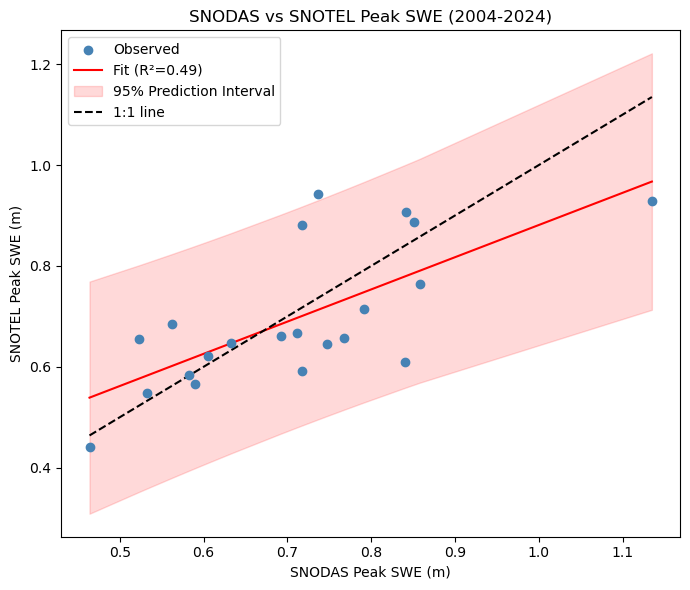

In [25]:
# SNODAS peak SWE as the predictor (X) and SNOTEL peak SWE as the response (Y)
import statsmodels.api as sm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

X_vals = peaks_df['peak_swe_snodas'].values
y_vals = peaks_df['peak_swe_snotel'].values

X_sm = sm.add_constant(X_vals)
model = sm.OLS(y_vals, X_sm).fit()

# Sort for clean shading
sort_idx = np.argsort(X_vals)
X_sorted = X_sm[sort_idx]
X_plot = X_vals[sort_idx]

predictions = model.get_prediction(X_sorted)
ci = predictions.summary_frame(alpha=0.05)

r2 = model.rsquared

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(X_vals, y_vals, color='steelblue', label='Observed', zorder=3)
ax.plot(X_plot, ci['mean'], color='red', label=f'Fit (R²={r2:.2f})')
ax.fill_between(X_plot, ci['obs_ci_lower'], ci['obs_ci_upper'],
                color='red', alpha=0.15, label='95% Prediction Interval')
ax.plot([X_vals.min(), X_vals.max()], [X_vals.min(), X_vals.max()],
        'k--', label='1:1 line')
ax.set_xlabel('SNODAS Peak SWE (m)')
ax.set_ylabel('SNOTEL Peak SWE (m)')
ax.set_title('SNODAS vs SNOTEL Peak SWE (2004-2024)')
ax.legend()
plt.tight_layout()
plt.savefig(r'../results/figures/SNODASvsSNOTELpeak_swe.png', dpi=300)
plt.show()

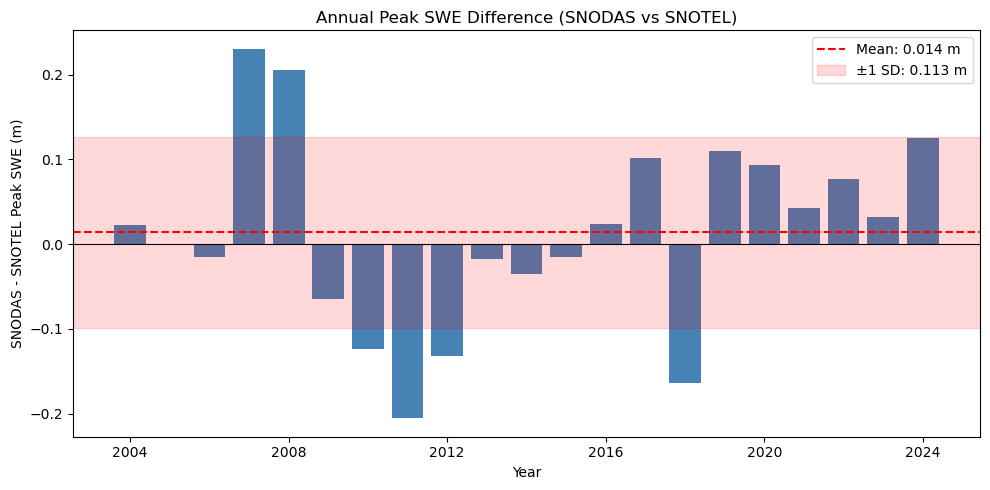

In [24]:
# --- Peak difference per year ---
import matplotlib.pyplot as plt
import numpy as np

mean_diff = peaks_df['peak_swe_diff_m'].mean()
std_diff = peaks_df['peak_swe_diff_m'].std()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(peaks_df['year'], peaks_df['peak_swe_diff_m'], color='steelblue')
ax.axhline(0, color='black', linewidth=0.8)
ax.axhline(mean_diff, color='red', linestyle='--', 
           label=f'Mean: {mean_diff:.3f} m')
ax.axhspan(mean_diff - std_diff, mean_diff + std_diff,
           color='red', alpha=0.15, 
           label=f'±1 SD: {std_diff:.3f} m')
ax.set_xlabel('Year')
ax.set_ylabel('SNODAS - SNOTEL Peak SWE (m)')
ax.set_title('Annual Peak SWE Difference (SNODAS vs SNOTEL)')
ax.set_xticks(range(2004, 2025, 4))
ax.legend()
plt.tight_layout()
plt.savefig(r'../results/figures/annual peak swe difference.png', dpi=300)
plt.show()

 year peak_date_snodas peak_date_snotel  peak_date_diff_days
 2004       2004-04-25       2004-04-23                    2
 2005       2005-05-04       2005-05-13                   -9
 2006       2006-04-19       2006-04-19                    0
 2007       2007-05-02       2007-04-27                    5
 2008       2008-06-14       2008-05-25                   20
 2009       2009-05-16       2009-05-15                    1
 2010       2010-05-14       2010-05-13                    1
 2011       2011-06-01       2011-05-31                    1
 2012       2012-05-08       2012-05-06                    2
 2013       2013-05-21       2013-04-24                   27
 2014       2014-05-01       2014-05-11                  -10
 2015       2015-05-20       2015-04-27                   23
 2016       2016-05-01       2016-04-29                    2
 2017       2017-05-03       2017-05-03                    0
 2018       2018-05-02       2018-04-24                    8
 2019       2019-05-09  

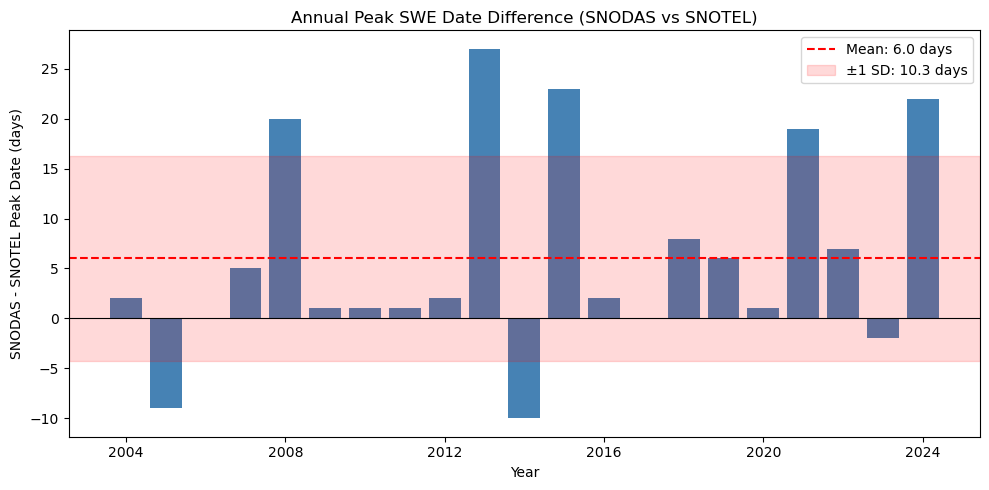

In [23]:
# --- Peak date difference per year ---
import matplotlib.pyplot as plt
import pandas as pd

peaks_df['peak_date_snodas'] = pd.to_datetime(peaks_df['peak_date_snodas'])
peaks_df['peak_date_snotel'] = pd.to_datetime(peaks_df['peak_date_snotel'])
peaks_df['peak_date_diff_days'] = (peaks_df['peak_date_snodas'] - peaks_df['peak_date_snotel']).dt.days

mean_diff = peaks_df['peak_date_diff_days'].mean()
std_diff = peaks_df['peak_date_diff_days'].std()

print(peaks_df[['year', 'peak_date_snodas', 'peak_date_snotel', 'peak_date_diff_days']].to_string(index=False))
print(f'\nMean difference: {mean_diff:.1f} days')
print(f'Mean absolute difference: {peaks_df["peak_date_diff_days"].abs().mean():.1f} days')
print(f'Std deviation: {std_diff:.1f} days')

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(peaks_df['year'], peaks_df['peak_date_diff_days'], color='steelblue')
ax.axhline(0, color='black', linewidth=0.8)
ax.axhline(mean_diff, color='red', linestyle='--',
           label=f'Mean: {mean_diff:.1f} days')
ax.axhspan(mean_diff - std_diff, mean_diff + std_diff,
           color='red', alpha=0.15,
           label=f'±1 SD: {std_diff:.1f} days')
ax.set_xlabel('Year')
ax.set_ylabel('SNODAS - SNOTEL Peak Date (days)')
ax.set_title('Annual Peak SWE Date Difference (SNODAS vs SNOTEL)')
ax.set_xticks(range(2004, 2025, 4))
ax.legend()
plt.tight_layout()
plt.savefig(r'../results/figures/annual peak swe date difference.png', dpi=300)
plt.show()

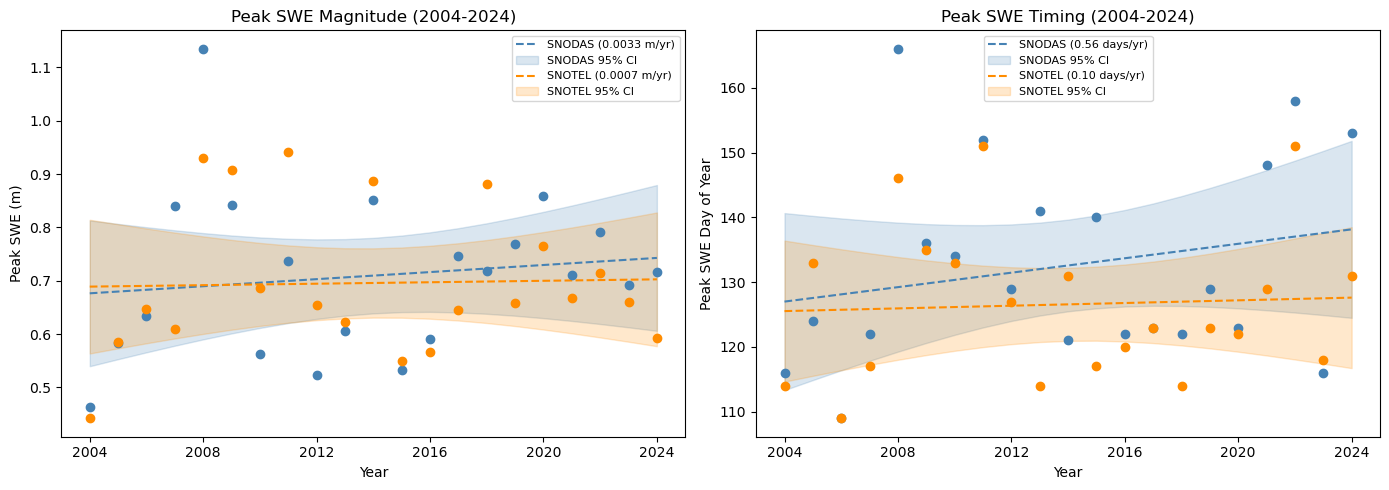

In [22]:
# Peak SWE (SNOTEL and SNODAS) vs. Year
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

years = peaks_df['year'].values
X = sm.add_constant(years)  # adds intercept column

def fit_ols_with_ci(x, y, X):
    model = sm.OLS(y, X).fit()
    predictions = model.get_prediction(X)
    ci = predictions.summary_frame(alpha=0.05)  # 95% CI
    return model, ci

# --- Left plot: Peak SWE magnitude ---
ax1 = axes[0]

model_snodas_mag, ci_snodas_mag = fit_ols_with_ci(years, peaks_df['peak_swe_snodas'], X)
model_snotel_mag, ci_snotel_mag = fit_ols_with_ci(years, peaks_df['peak_swe_snotel'], X)

ax1.scatter(years, peaks_df['peak_swe_snodas'], color='steelblue', zorder=3)
ax1.scatter(years, peaks_df['peak_swe_snotel'], color='darkorange', zorder=3)

ax1.plot(years, ci_snodas_mag['mean'], color='steelblue', linestyle='--', 
         label=f'SNODAS ({model_snodas_mag.params.iloc[1]:.4f} m/yr)')
ax1.fill_between(years, ci_snodas_mag['mean_ci_lower'], ci_snodas_mag['mean_ci_upper'],
                 color='steelblue', alpha=0.2, label='SNODAS 95% CI')

ax1.plot(years, ci_snotel_mag['mean'], color='darkorange', linestyle='--',
         label=f'SNOTEL ({model_snotel_mag.params.iloc[1]:.4f} m/yr)')
ax1.fill_between(years, ci_snotel_mag['mean_ci_lower'], ci_snotel_mag['mean_ci_upper'],
                 color='darkorange', alpha=0.2, label='SNOTEL 95% CI')

ax1.set_xlabel('Year')
ax1.set_ylabel('Peak SWE (m)')
ax1.set_title('Peak SWE Magnitude (2004-2024)')
ax1.set_xticks(range(2004, 2025, 4))
ax1.legend(fontsize=8)

# --- Right plot: Peak SWE timing (DOY) ---
ax2 = axes[1]

model_snodas_doy, ci_snodas_doy = fit_ols_with_ci(years, peaks_df['peak_doy_snodas'], X)
model_snotel_doy, ci_snotel_doy = fit_ols_with_ci(years, peaks_df['peak_doy_snotel'], X)

ax2.scatter(years, peaks_df['peak_doy_snodas'], color='steelblue', zorder=3)
ax2.scatter(years, peaks_df['peak_doy_snotel'], color='darkorange', zorder=3)

ax2.plot(years, ci_snodas_doy['mean'], color='steelblue', linestyle='--',
         label=f'SNODAS ({model_snodas_doy.params.iloc[1]:.2f} days/yr)')
ax2.fill_between(years, ci_snodas_doy['mean_ci_lower'], ci_snodas_doy['mean_ci_upper'],
                 color='steelblue', alpha=0.2, label='SNODAS 95% CI')

ax2.plot(years, ci_snotel_doy['mean'], color='darkorange', linestyle='--',
         label=f'SNOTEL ({model_snotel_doy.params.iloc[1]:.2f} days/yr)')
ax2.fill_between(years, ci_snotel_doy['mean_ci_lower'], ci_snotel_doy['mean_ci_upper'],
                 color='darkorange', alpha=0.2, label='SNOTEL 95% CI')

ax2.set_xlabel('Year')
ax2.set_ylabel('Peak SWE Day of Year')
ax2.set_title('Peak SWE Timing (2004-2024)')
ax2.set_xticks(range(2004, 2025, 4))
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig(r'../results/figures/peak_swe_trends.png', dpi=300)
plt.show()

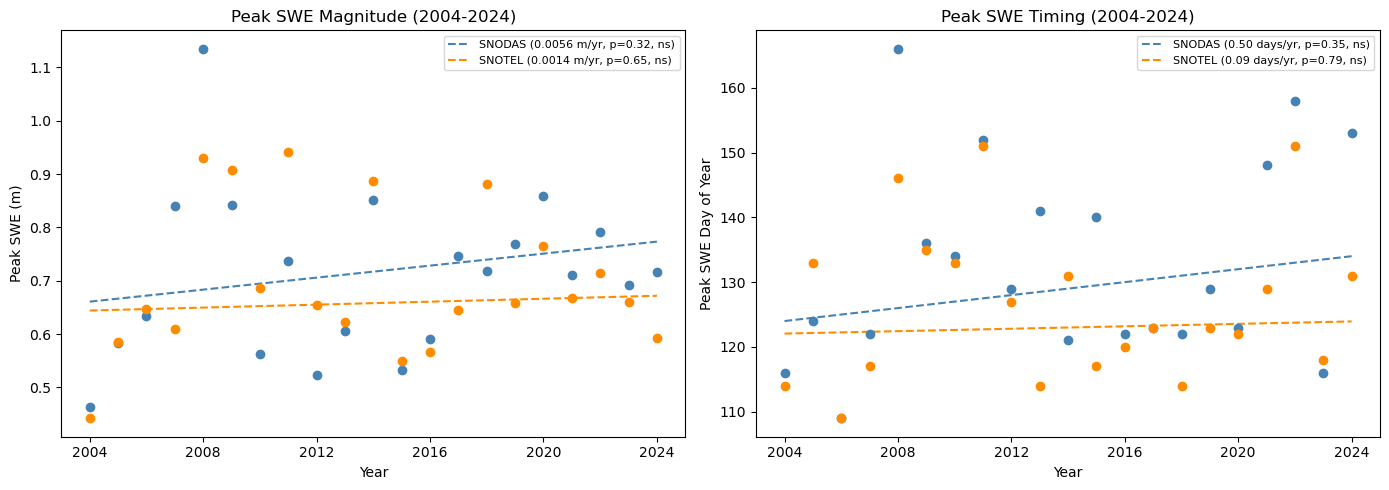

In [26]:
# Peak SWE (SNOTEL and SNODAS) vs. Year with Theil-Sen regression line and statistics

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import theilslopes

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

years = peaks_df['year'].values

def theilsen_line(x, y):
    x_centered = x - x.mean()
    res = theilslopes(y, x_centered, alpha=0.05)
    line = res.slope * x_centered + res.intercept
    return line, res.slope

# Mann-Kendall p-values
p_snodas_mag = 0.3190
p_snotel_mag = 0.6506
p_snodas_doy = 0.3477
p_snotel_doy = 0.7850

# --- Left plot: Peak SWE magnitude ---
ax1 = axes[0]

snodas_mag, snodas_mag_slope = theilsen_line(years, peaks_df['peak_swe_snodas'])
snotel_mag, snotel_mag_slope = theilsen_line(years, peaks_df['peak_swe_snotel'])

ax1.scatter(years, peaks_df['peak_swe_snodas'], color='steelblue', zorder=3)
ax1.scatter(years, peaks_df['peak_swe_snotel'], color='darkorange', zorder=3)
ax1.plot(years, snodas_mag, color='steelblue', linestyle='--',
         label=f'SNODAS ({snodas_mag_slope:.4f} m/yr, p={p_snodas_mag:.2f}, ns)')
ax1.plot(years, snotel_mag, color='darkorange', linestyle='--',
         label=f'SNOTEL ({snotel_mag_slope:.4f} m/yr, p={p_snotel_mag:.2f}, ns)')

ax1.set_xlabel('Year')
ax1.set_ylabel('Peak SWE (m)')
ax1.set_title('Peak SWE Magnitude (2004-2024)')
ax1.set_xticks(range(2004, 2025, 4))
ax1.legend(fontsize=8)

# --- Right plot: Peak SWE timing (DOY) ---
ax2 = axes[1]

snodas_doy, snodas_doy_slope = theilsen_line(years, peaks_df['peak_doy_snodas'])
snotel_doy, snotel_doy_slope = theilsen_line(years, peaks_df['peak_doy_snotel'])

ax2.scatter(years, peaks_df['peak_doy_snodas'], color='steelblue', zorder=3)
ax2.scatter(years, peaks_df['peak_doy_snotel'], color='darkorange', zorder=3)
ax2.plot(years, snodas_doy, color='steelblue', linestyle='--',
         label=f'SNODAS ({snodas_doy_slope:.2f} days/yr, p={p_snodas_doy:.2f}, ns)')
ax2.plot(years, snotel_doy, color='darkorange', linestyle='--',
         label=f'SNOTEL ({snotel_doy_slope:.2f} days/yr, p={p_snotel_doy:.2f}, ns)')

ax2.set_xlabel('Year')
ax2.set_ylabel('Peak SWE Day of Year')
ax2.set_title('Peak SWE Timing (2004-2024)')
ax2.set_xticks(range(2004, 2025, 4))
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig(r'../results/figures/peak_swe_trends2.png', dpi=300)
plt.show()

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.493
Model:                            OLS   Adj. R-squared:                  0.466
Method:                 Least Squares   F-statistic:                     18.48
Date:                Thu, 23 Apr 2026   Prob (F-statistic):           0.000388
Time:                        10:36:40   Log-Likelihood:                 19.329
No. Observations:                  21   AIC:                            -34.66
Df Residuals:                      19   BIC:                            -32.57
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2427      0.108      2.254      0.0

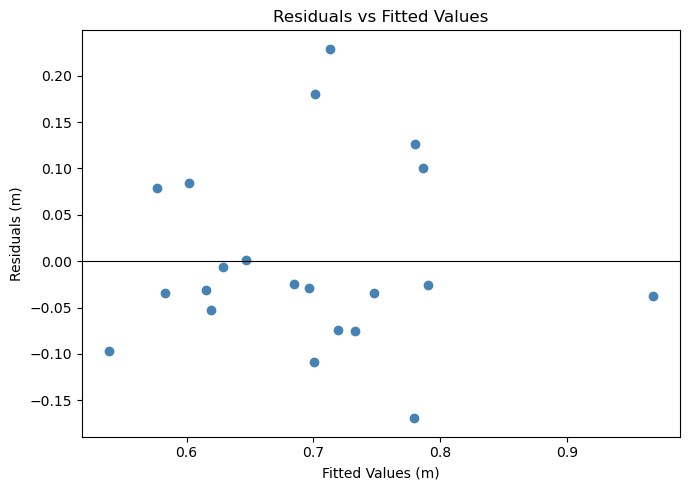

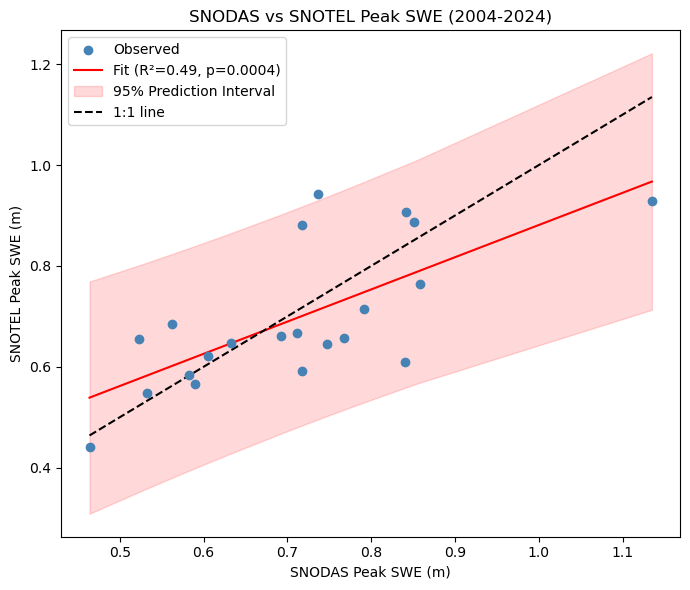

In [14]:
# Simple linear regression with hypothesis testing (SWE)
# Is there a statistically significant linear relationship between SNODAS and SNOTEL peak SWE?
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

output_dir = "../results/figures"
os.makedirs(output_dir, exist_ok=True)

peaks_df = pd.read_csv(r'MERGED/peaks_swe.csv', parse_dates=['peak_date_snodas', 'peak_date_snotel'])

X = peaks_df['peak_swe_snodas'].values
y = peaks_df['peak_swe_snotel'].values

# --- OLS regression with full statistical output ---
X_sm = sm.add_constant(X)
model = sm.OLS(y, X_sm).fit()

print(model.summary())

# --- Key metrics ---
y_pred = model.predict(X_sm)
mae  = mean_absolute_error(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))
bias = np.mean(y_pred - y)

print('\n=== ADDITIONAL METRICS ===')
print(f'MAE:  {mae:.4f} m')
print(f'RMSE: {rmse:.4f} m')
print(f'Bias: {bias:.4f} m (positive = SNODAS overestimates)')

# --- Save results ---
import csv

results = {
    'R_squared':        model.rsquared,
    'Adj_R_squared':    model.rsquared_adj,
    'F_statistic':      model.fvalue,
    'F_pvalue':         model.f_pvalue,
    'intercept':        model.params[0],
    'intercept_pvalue': model.pvalues[0],
    'slope':            model.params[1],
    'slope_pvalue':     model.pvalues[1],
    'MAE':              mae,
    'RMSE':             rmse,
    'Bias':             bias,
    'N':                int(model.nobs)
}

pd.DataFrame([results]).to_csv(r'../results/regression_results_swe.csv', index=False)

# Assumptions:
# 1. Linearity
# The relationship between X and Y is linear. Violated if the true relationship is curved or exponential.
# Check by inspecting the scatterplot — your SNODAS vs SNOTEL plot should show a roughly linear cloud of points.

# 2. Independence of observations
# Each observation is independent of the others. For your data this means each year's peak SWE is independent of other years. 
# Annual peak values generally satisfy this since each snow season starts fresh, though consecutive years with similar climate drivers could introduce mild dependence.

# 3. Homoscedasticity
# The variance of the residuals is constant across all values of X. Violated if errors are larger at high SWE values than low ones (or vice versa). 
# Check by plotting residuals vs fitted values — you want a random horizontal scatter with no funnel shape.

# 4. Normality of residuals
# The residuals are normally distributed. This is needed for valid hypothesis tests and confidence intervals. 
# Your Prob(Omnibus) = 0.242 and Prob(JB) = 0.393 both indicate residuals do not significantly deviate from normality, so this assumption is satisfied.

# 5. No multicollinearity
# Predictors are not perfectly correlated with each other. Not relevant here since you only have one predictor (SNODAS).

# --- Checking homoscedasticity ---
fig, ax = plt.subplots(figsize=(7, 5))
residuals = y - y_pred
ax.scatter(y_pred, residuals, color='steelblue')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Fitted Values (m)')
ax.set_ylabel('Residuals (m)')
ax.set_title('Residuals vs Fitted Values')
plt.tight_layout()
plt.savefig(r'../results/figures/residuals_plot_swe.png', dpi=300)
plt.show()

# --- Plot ---
sort_idx = np.argsort(X)
X_sorted = X_sm[sort_idx]
X_plot   = X[sort_idx]

predictions = model.get_prediction(X_sorted)
ci = predictions.summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(X, y, color='steelblue', label='Observed', zorder=3)
ax.plot(X_plot, ci['mean'], color='red',
        label=f'Fit (R²={model.rsquared:.2f}, p={model.f_pvalue:.4f})')
ax.fill_between(X_plot, ci['obs_ci_lower'], ci['obs_ci_upper'],
                color='red', alpha=0.15, label='95% Prediction Interval')
ax.plot([X.min(), X.max()], [X.min(), X.max()],
        'k--', label='1:1 line')
ax.set_xlabel('SNODAS Peak SWE (m)')
ax.set_ylabel('SNOTEL Peak SWE (m)')
ax.set_title('SNODAS vs SNOTEL Peak SWE (2004-2024)')
ax.legend()
plt.tight_layout()
plt.savefig(r'../results/figures/snodas_vs_snotel_regression_swe.png', dpi=300)
plt.show()

# R² — proportion of SNOTEL variance explained by SNODAS
# F-statistic and p-value — tests whether the overall model is significant
# Slope coefficient and p-value — tests whether SNODAS is a significant predictor
# Confidence interval on slope — range of plausible slope values
# Durbin-Watson statistic — checks for autocorrelation in residuals

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.558
Model:                            OLS   Adj. R-squared:                  0.535
Method:                 Least Squares   F-statistic:                     24.01
Date:                Thu, 23 Apr 2026   Prob (F-statistic):           9.95e-05
Time:                        10:35:50   Log-Likelihood:                -72.960
No. Observations:                  21   AIC:                             149.9
Df Residuals:                      19   BIC:                             152.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         49.5384     15.824      3.131      0.0

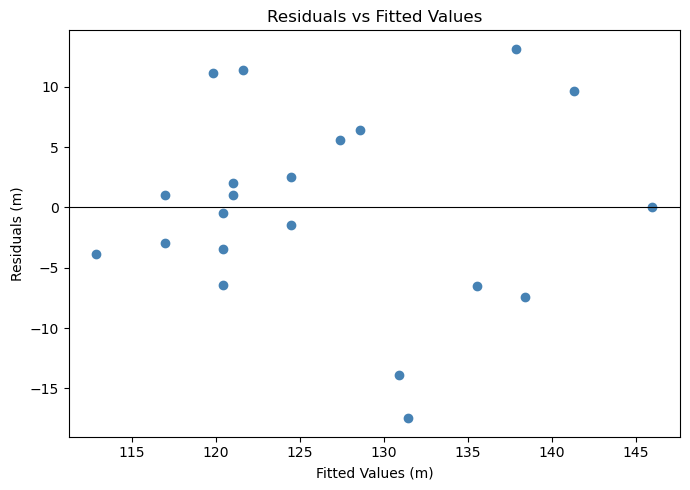

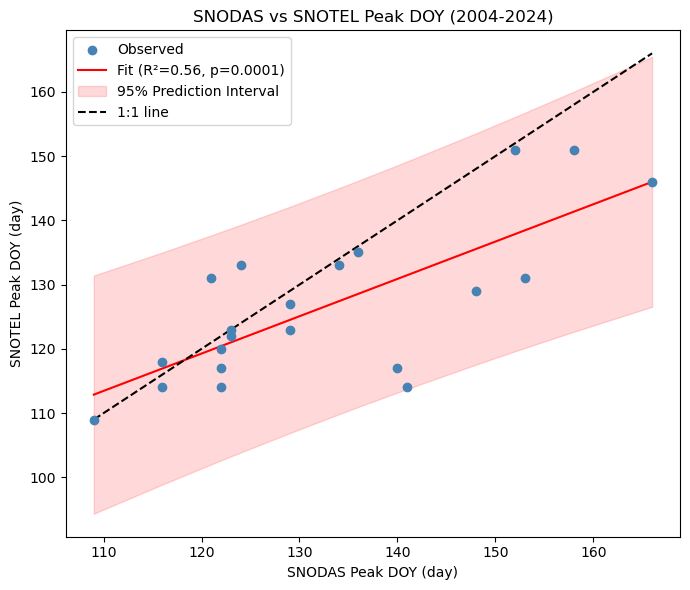

In [13]:
# Simple linear regression with hypothesis testing (DOY)
# Is there a statistically significant linear relationship between SNODAS and SNOTEL peak doy?
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

output_dir = "../results/figures"
os.makedirs(output_dir, exist_ok=True)

peaks_df = pd.read_csv(r'MERGED/peaks_swe.csv', parse_dates=['peak_date_snodas', 'peak_date_snotel'])

X = peaks_df['peak_doy_snodas'].values
y = peaks_df['peak_doy_snotel'].values

# --- OLS regression with full statistical output ---
X_sm = sm.add_constant(X)
model = sm.OLS(y, X_sm).fit()

print(model.summary())

# --- Key metrics ---
y_pred = model.predict(X_sm)
mae  = mean_absolute_error(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))
bias = np.mean(y_pred - y)

print('\n=== ADDITIONAL METRICS ===')
print(f'MAE:  {mae:.4f} m')
print(f'RMSE: {rmse:.4f} m')
print(f'Bias: {bias:.4f} m (positive = SNODAS overestimates)')

# --- Save results ---
import csv

results = {
    'R_squared':        model.rsquared,
    'Adj_R_squared':    model.rsquared_adj,
    'F_statistic':      model.fvalue,
    'F_pvalue':         model.f_pvalue,
    'intercept':        model.params[0],
    'intercept_pvalue': model.pvalues[0],
    'slope':            model.params[1],
    'slope_pvalue':     model.pvalues[1],
    'MAE':              mae,
    'RMSE':             rmse,
    'Bias':             bias,
    'N':                int(model.nobs)
}

pd.DataFrame([results]).to_csv(r'../results/regression_results_doy.csv', index=False)

# Assumptions:
# 1. Linearity
# The relationship between X and Y is linear. Violated if the true relationship is curved or exponential.
# Check by inspecting the scatterplot — your SNODAS vs SNOTEL plot should show a roughly linear cloud of points.

# 2. Independence of observations
# Each observation is independent of the others. For your data this means each year's peak SWE is independent of other years. 
# Annual peak values generally satisfy this since each snow season starts fresh, though consecutive years with similar climate drivers could introduce mild dependence.

# 3. Homoscedasticity
# The variance of the residuals is constant across all values of X. Violated if errors are larger at high SWE values than low ones (or vice versa). 
# Check by plotting residuals vs fitted values — you want a random horizontal scatter with no funnel shape.

# 4. Normality of residuals
# The residuals are normally distributed. This is needed for valid hypothesis tests and confidence intervals. 
# Your Prob(Omnibus) = 0.242 and Prob(JB) = 0.393 both indicate residuals do not significantly deviate from normality, so this assumption is satisfied.

# 5. No multicollinearity
# Predictors are not perfectly correlated with each other. Not relevant here since you only have one predictor (SNODAS).

# --- Checking homoscedasticity ---
fig, ax = plt.subplots(figsize=(7, 5))
residuals = y - y_pred
ax.scatter(y_pred, residuals, color='steelblue')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Fitted Values (m)')
ax.set_ylabel('Residuals (m)')
ax.set_title('Residuals vs Fitted Values')
plt.tight_layout()
plt.savefig(r'../results/figures/residuals_plot_doy.png', dpi=300)
plt.show()

# --- Plot ---
sort_idx = np.argsort(X)
X_sorted = X_sm[sort_idx]
X_plot   = X[sort_idx]

predictions = model.get_prediction(X_sorted)
ci = predictions.summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(X, y, color='steelblue', label='Observed', zorder=3)
ax.plot(X_plot, ci['mean'], color='red',
        label=f'Fit (R²={model.rsquared:.2f}, p={model.f_pvalue:.4f})')
ax.fill_between(X_plot, ci['obs_ci_lower'], ci['obs_ci_upper'],
                color='red', alpha=0.15, label='95% Prediction Interval')
ax.plot([X.min(), X.max()], [X.min(), X.max()],
        'k--', label='1:1 line')
ax.set_xlabel('SNODAS Peak DOY (day)')
ax.set_ylabel('SNOTEL Peak DOY (day)')
ax.set_title('SNODAS vs SNOTEL Peak DOY (2004-2024)')
ax.legend()
plt.tight_layout()
plt.savefig(r'../results/figures/snodas_vs_snotel_regression_doy.png', dpi=300)
plt.show()

# R² — proportion of SNOTEL variance explained by SNODAS
# F-statistic and p-value — tests whether the overall model is significant
# Slope coefficient and p-value — tests whether SNODAS is a significant predictor
# Confidence interval on slope — range of plausible slope values
# Durbin-Watson statistic — checks for autocorrelation in residuals

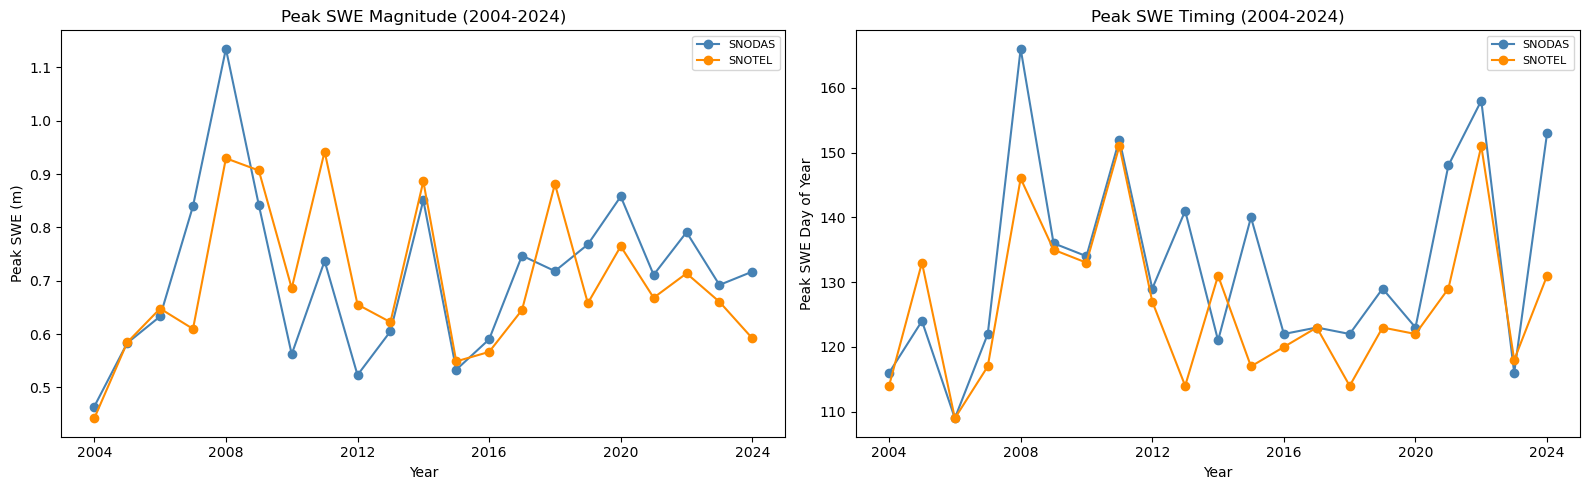

In [46]:
# Time Series, Peak SWE and Peak SWE DOY
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

years = peaks_df['year'].values

# --- Left plot: Peak SWE magnitude ---
ax1 = axes[0]
ax1.plot(years, peaks_df['peak_swe_snodas'], 'o-', color='steelblue', label='SNODAS')
ax1.plot(years, peaks_df['peak_swe_snotel'], 'o-', color='darkorange', label='SNOTEL')
ax1.set_xlabel('Year')
ax1.set_ylabel('Peak SWE (m)')
ax1.set_title('Peak SWE Magnitude (2004-2024)')
ax1.set_xticks(range(2004, 2025, 4))
ax1.legend(fontsize=8)

# --- Right plot: Peak DOY ---
ax2 = axes[1]
ax2.plot(years, peaks_df['peak_doy_snodas'], 'o-', color='steelblue', label='SNODAS')
ax2.plot(years, peaks_df['peak_doy_snotel'], 'o-', color='darkorange', label='SNOTEL')
ax2.set_xlabel('Year')
ax2.set_ylabel('Peak SWE Day of Year')
ax2.set_title('Peak SWE Timing (2004-2024)')
ax2.set_xticks(range(2004, 2025, 4))
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig(r'../results/figures/timeseries.png', dpi=300)
plt.show()

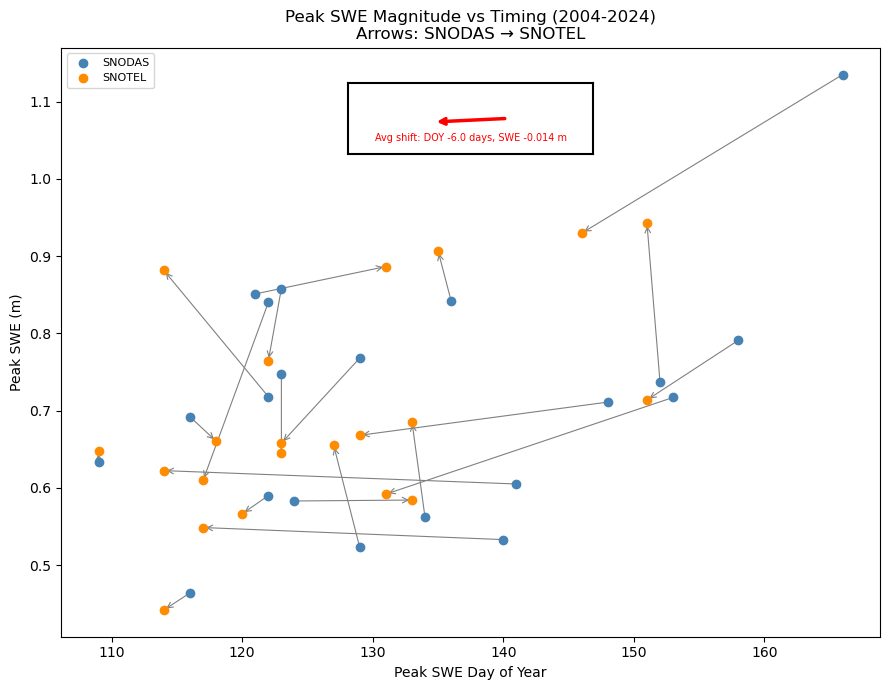

In [60]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(9, 7))

# --- Connected dot plot: DOY on x, SWE on y ---
for _, row in peaks_df.iterrows():
    ax.annotate('',
                xy=(row['peak_doy_snotel'], row['peak_swe_snotel']),
                xytext=(row['peak_doy_snodas'], row['peak_swe_snodas']),
                arrowprops=dict(arrowstyle='->', color='gray', lw=0.8))

ax.scatter(peaks_df['peak_doy_snodas'], peaks_df['peak_swe_snodas'],
           color='steelblue', label='SNODAS', zorder=3)
ax.scatter(peaks_df['peak_doy_snotel'], peaks_df['peak_swe_snotel'],
           color='darkorange', label='SNOTEL', zorder=3)

# --- Average direction arrow ---
mean_dx = (peaks_df['peak_doy_snotel'] - peaks_df['peak_doy_snodas']).mean()
mean_dy = (peaks_df['peak_swe_snotel'] - peaks_df['peak_swe_snodas']).mean()

x_range = peaks_df[['peak_doy_snodas', 'peak_doy_snotel']].values.max() - peaks_df[['peak_doy_snodas', 'peak_doy_snotel']].values.min()
y_range = peaks_df[['peak_swe_snodas', 'peak_swe_snotel']].values.max() - peaks_df[['peak_swe_snodas', 'peak_swe_snotel']].values.min()

magnitude = np.sqrt(mean_dx**2 + mean_dy**2)
scale = 0.08
norm_dx = (mean_dx / magnitude) * scale * x_range
norm_dy = (mean_dy / magnitude) * scale * y_range

# Place arrow at top center of plot in axes coordinates
x_min = peaks_df[['peak_doy_snodas', 'peak_doy_snotel']].values.min()
x_max = peaks_df[['peak_doy_snodas', 'peak_doy_snotel']].values.max()
y_max = peaks_df[['peak_swe_snodas', 'peak_swe_snotel']].values.max()

arrow_x = (x_min + x_max) / 2
arrow_y = y_max - y_range * 0.05

# Draw inset box using axes fraction coordinates
box = ax.inset_axes([0.35, 0.82, 0.30, 0.12])  # [x, y, width, height] in axes fraction
box.set_xticks([])
box.set_yticks([])
for spine in box.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(1.5)
box.set_facecolor('white')

# Arrow inside inset box
box.annotate('',
             xy=(0.35, 0.45),
             xytext=(0.65, 0.5),
             xycoords='axes fraction',
             textcoords='axes fraction',
             arrowprops=dict(arrowstyle='->', color='red', lw=2.5))
box.text(0.5, 0.15,
         f'Avg shift: DOY {mean_dx:+.1f} days, SWE {mean_dy:+.3f} m',
         fontsize=7, ha='center', va='bottom',
         transform=box.transAxes, color='red')

ax.set_xlabel('Peak SWE Day of Year')
ax.set_ylabel('Peak SWE (m)')
ax.set_title('Peak SWE Magnitude vs Timing (2004-2024)\nArrows: SNODAS → SNOTEL')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(r'../results/figures/connected_dot_doy_swe.png', dpi=300)
plt.show()